# Multi-Layer Perceptron (Keras) - Thanthrige P.D.I. (IT25100170)


## 1. Model Suitability

**Why MLP (Keras) for Wisconsin Breast Cancer?**

- Neural networks can model complex non-linear decision boundaries.
- Dataset is small but clean after preprocessing -> a modest MLP can achieve high accuracy without overfitting if regularised.
- Keras/TensorFlow gives full control over architecture, activation, optimisers, dropout, etc.
- Good educational demonstration of deep-learning concepts on a classic tabular problem.
- No pretrained models are used – network is built and trained from random initialisation.


In [ ]:
# Standard libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, roc_auc_score, roc_curve)

# TensorFlow / Keras
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, callbacks, regularizers

print("TensorFlow version:", tf.__version__)
print("Libraries imported successfully.")

# Reproducibility
np.random.seed(42)
tf.random.set_seed(42)

TensorFlow version: 2.21.0
Libraries imported successfully.


In [ ]:
# ============================================================
# GOOGLE DRIVE MOUNT & LOAD PREPROCESSED DATA
# Student: Thanthrige P.D.I. (IT25100170)
# Algorithm: MLP (Keras)
# ============================================================
from google.colab import drive
drive.mount('/content/drive')

DATA_PATH = '/content/drive/MyDrive/Y2S1/AI_ML/Project/Progress Review/Group_26-MTR-IT2011-04/results/outputs/processed_breast_cancer.csv'
df = pd.read_csv(DATA_PATH)
print("Dataset shape:", df.shape)
print(df['Class'].value_counts())
df.head()

Mounted at /content/drive
Dataset shape: (699, 20)
Class
0    458
1    241
Name: count, dtype: int64


,Sample_code_number,Clump_Thickness,Uniformity_of_Cell_Size,Uniformity_of_Cell_Shape,Marginal_Adhesion,Single_Epithelial_Cell_Size,Bare_Nuclei,Bland_Chromatin,Normal_Nucleoli,Mitoses,Clump_Thickness_scaled,Uniformity_of_Cell_Size_scaled,Uniformity_of_Cell_Shape_scaled,Marginal_Adhesion_scaled,Single_Epithelial_Cell_Size_scaled,Bare_Nuclei_scaled,Bland_Chromatin_scaled,Normal_Nucleoli_scaled,Mitoses_scaled,Class
0,1000025,5.0,1.0,1.0,1.0,2.0,1.0,3.0,1.0,1.0,0.206936,-0.699995,-0.743299,-0.633247,-0.549561,-0.686979,-0.179662,-0.611825,-0.343912,0
1,1002945,5.0,4.0,4.0,5.0,7.0,10.0,3.0,2.0,1.0,0.206936,0.283845,0.266875,0.768621,1.710106,1.799664,-0.179662,-0.284112,-0.343912,0
2,1015425,3.0,1.0,1.0,1.0,2.0,2.0,3.0,1.0,1.0,-0.503866,-0.699995,-0.743299,-0.633247,-0.549561,-0.410685,-0.179662,-0.611825,-0.343912,0
3,1016277,6.0,8.0,8.0,1.0,3.0,4.0,3.0,7.0,1.0,0.562336,1.595632,1.613773,-0.633247,-0.097628,0.141902,-0.179662,1.354454,-0.343912,0
4,1017023,4.0,1.0,1.0,3.0,2.0,1.0,3.0,1.0,1.0,-0.148465,-0.699995,-0.743299,0.067687,-0.549561,-0.686979,-0.179662,-0.611825,-0.343912,0


In [ ]:
# DATA PREPARATION
df = df.drop(columns=['Sample_code_number'], errors='ignore')
feature_cols_orig = [
    'Clump_Thickness', 'Uniformity_of_Cell_Size', 'Uniformity_of_Cell_Shape',
    'Marginal_Adhesion', 'Single_Epithelial_Cell_Size', 'Bare_Nuclei',
    'Bland_Chromatin', 'Normal_Nucleoli', 'Mitoses'
]
feature_cols_scaled = [c + '_scaled' for c in feature_cols_orig]

X_scaled = df[feature_cols_scaled].values.astype('float32')
y = df['Class'].values.astype('float32')

print("Features shape:", X_scaled.shape)
print("Class balance :", np.bincount(y.astype(int)))

Features shape: (699, 9)
Class balance : [458 241]


In [ ]:
# TRAIN / VAL / TEST SPLIT (60 / 20 / 20) – stratified
X_temp, X_test, y_temp, y_test = train_test_split(
    X_scaled, y, test_size=0.20, random_state=42, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.25, random_state=42, stratify=y_temp  # 0.25 of 80% = 20%
)
print("Train:", X_train.shape, "| Val:", X_val.shape, "| Test:", X_test.shape)
print("Train class dist:", np.bincount(y_train.astype(int)))

Train: (419, 9) | Val: (140, 9) | Test: (140, 9)
Train class dist: [274 145]


In [ ]:
# Evaluation helper
def evaluate_keras_model(model, X_test, y_test, model_name="Model"):
    y_prob = model.predict(X_test, verbose=0).ravel()
    y_pred = (y_prob >= 0.5).astype(int)
    metrics = {
        'Model': model_name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1-Score': f1_score(y_test, y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, y_prob)
    }
    print(f"\n========== {model_name} ==========")
    print(classification_report(y_test, y_pred, target_names=['Benign (0)', 'Malignant (1)']))
    print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
    print(f"ROC-AUC: {metrics['ROC-AUC']:.4f}")
    return metrics, y_pred, y_prob

## 2. Implementation – MLP Varieties

| Variety | Architecture | Regularisation / Notes |
|---------|--------------|------------------------|
| V1 Baseline | 16 -> 8 -> 1 | No dropout, Adam default |
| V2 Deeper + Dropout | 64 -> 32 -> 16 -> 1 | Dropout 0.3, L2 |
| V3 Wide + BatchNorm | 128 -> 64 -> 1 | BatchNorm, Dropout |
| V4 Tuned (best practice) | 32 -> 16 -> 1 | EarlyStopping, ReduceLR, class weights |


In [ ]:
# ------------------------------------------------------------
# Variety 1 – Simple Baseline MLP
# ------------------------------------------------------------
def build_mlp_v1(input_dim=9):
    model = keras.Sequential([
        layers.Input(shape=(input_dim,)),
        layers.Dense(16, activation='relu'),
        layers.Dense(8, activation='relu'),
        layers.Dense(1, activation='sigmoid')
    ], name='MLP_V1_Baseline')
    model.compile(optimizer='adam', loss='binary_crossentropy',
                  metrics=['accuracy', keras.metrics.AUC(name='auc')])
    return model

mlp_v1 = build_mlp_v1()
mlp_v1.summary()

history_v1 = mlp_v1.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=32,
    verbose=0
)
metrics_v1, y_pred_v1, y_prob_v1 = evaluate_keras_model(mlp_v1, X_test, y_test, "V1: MLP Baseline (16-8-1)")

Model: "MLP_V1_Baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 305 (1.19 KB)

 Trainable params: 305 (1.19 KB)

 Non-trainable params: 0 (0.00 B)


========== V1: MLP Baseline (16-8-1) ==========
               precision    recall  f1-score   support

   Benign (0)       0.99      0.96      0.97        92
Malignant (1)       0.92      0.98      0.95        48

     accuracy                           0.96       140
    macro avg       0.96      0.97      0.96       140
 weighted avg       0.97      0.96      0.96       140

Confusion Matrix:
 [[88  4]
 [ 1 47]]
ROC-AUC: 0.9930


In [ ]:
# ------------------------------------------------------------
# Variety 2 – Deeper network with Dropout + L2
# ------------------------------------------------------------
def build_mlp_v2(input_dim=9):
    model = keras.Sequential([
        layers.Input(shape=(input_dim,)),
        layers.Dense(64, activation='relu', kernel_regularizer=regularizers.l2(1e-4)),
        layers.Dropout(0.3),
        layers.Dense(32, activation='relu', kernel_regularizer=regularizers.l2(1e-4)),
        layers.Dropout(0.3),
        layers.Dense(16, activation='relu'),
        layers.Dense(1, activation='sigmoid')
    ], name='MLP_V2_Deep_Dropout')
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
                  loss='binary_crossentropy',
                  metrics=['accuracy', keras.metrics.AUC(name='auc')])
    return model

mlp_v2 = build_mlp_v2()
mlp_v2.summary()

history_v2 = mlp_v2.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=150,
    batch_size=32,
    verbose=0
)
metrics_v2, y_pred_v2, y_prob_v2 = evaluate_keras_model(mlp_v2, X_test, y_test, "V2: MLP Deep + Dropout")

Model: "MLP_V2_Deep_Dropout"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 64)             │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,265 (12.75 KB)

 Trainable params: 3,265 (12.75 KB)

 Non-trainable params: 0 (0.00 B)


========== V2: MLP Deep + Dropout ==========
               precision    recall  f1-score   support

   Benign (0)       0.99      0.96      0.97        92
Malignant (1)       0.92      0.98      0.95        48

     accuracy                           0.96       140
    macro avg       0.96      0.97      0.96       140
 weighted avg       0.97      0.96      0.96       140

Confusion Matrix:
 [[88  4]
 [ 1 47]]
ROC-AUC: 0.9885


In [ ]:
# ------------------------------------------------------------
# Variety 3 – Wide + BatchNormalization
# ------------------------------------------------------------
def build_mlp_v3(input_dim=9):
    model = keras.Sequential([
        layers.Input(shape=(input_dim,)),
        layers.Dense(128, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.4),
        layers.Dense(64, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.3),
        layers.Dense(1, activation='sigmoid')
    ], name='MLP_V3_Wide_BN')
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
                  loss='binary_crossentropy',
                  metrics=['accuracy', keras.metrics.AUC(name='auc')])
    return model

mlp_v3 = build_mlp_v3()
mlp_v3.summary()

history_v3 = mlp_v3.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=150,
    batch_size=16,
    verbose=0
)
metrics_v3, y_pred_v3, y_prob_v3 = evaluate_keras_model(mlp_v3, X_test, y_test, "V3: MLP Wide + BatchNorm")

Model: "MLP_V3_Wide_BN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_7 (Dense)                 │ (None, 128)            │         1,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,369 (40.50 KB)

 Trainable params: 9,985 (39.00 KB)

 Non-trainable params: 384 (1.50 KB)


========== V3: MLP Wide + BatchNorm ==========
               precision    recall  f1-score   support

   Benign (0)       0.95      0.96      0.95        92
Malignant (1)       0.91      0.90      0.91        48

     accuracy                           0.94       140
    macro avg       0.93      0.93      0.93       140
 weighted avg       0.94      0.94      0.94       140

Confusion Matrix:
 [[88  4]
 [ 5 43]]
ROC-AUC: 0.9903


In [ ]:
# ------------------------------------------------------------
# Variety 4 – Best-practice: EarlyStopping + ReduceLR + class weight
# ------------------------------------------------------------
def build_mlp_v4(input_dim=9):
    model = keras.Sequential([
        layers.Input(shape=(input_dim,)),
        layers.Dense(32, activation='relu', kernel_regularizer=regularizers.l2(1e-4)),
        layers.Dropout(0.25),
        layers.Dense(16, activation='relu', kernel_regularizer=regularizers.l2(1e-4)),
        layers.Dropout(0.25),
        layers.Dense(1, activation='sigmoid')
    ], name='MLP_V4_Tuned')
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
                  loss='binary_crossentropy',
                  metrics=['accuracy', keras.metrics.AUC(name='auc')])
    return model

# Class weights (handle mild imbalance)
n_benign = np.sum(y_train == 0)
n_malig  = np.sum(y_train == 1)
class_weight = {0: 1.0, 1: n_benign / n_malig}
print("Class weights:", class_weight)

early_stop = callbacks.EarlyStopping(monitor='val_loss', patience=20, restore_best_weights=True, verbose=1)
reduce_lr  = callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=8, min_lr=1e-6, verbose=1)

mlp_v4 = build_mlp_v4()
mlp_v4.summary()

history_v4 = mlp_v4.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=200,
    batch_size=32,
    class_weight=class_weight,
    callbacks=[early_stop, reduce_lr],
    verbose=0
)
metrics_v4, y_pred_v4, y_prob_v4 = evaluate_keras_model(mlp_v4, X_test, y_test, "V4: MLP Tuned (EarlyStop + LR + CW)")

Class weights: {0: 1.0, 1: np.float64(1.889655172413793)}


Model: "MLP_V4_Tuned"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_10 (Dense)                │ (None, 32)             │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 865 (3.38 KB)

 Trainable params: 865 (3.38 KB)

 Non-trainable params: 0 (0.00 B)


Epoch 19: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.

Epoch 27: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
Epoch 31: early stopping
Restoring model weights from the end of the best epoch: 11.

========== V4: MLP Tuned (EarlyStop + LR + CW) ==========
               precision    recall  f1-score   support

   Benign (0)       0.98      0.96      0.97        92
Malignant (1)       0.92      0.96      0.94        48

     accuracy                           0.96       140
    macro avg       0.95      0.96      0.95       140
 weighted avg       0.96      0.96      0.96       140

Confusion Matrix:
 [[88  4]
 [ 2 46]]
ROC-AUC: 0.9939


## 3. Comparison Across Varieties

In [ ]:
results_df = pd.DataFrame([metrics_v1, metrics_v2, metrics_v3, metrics_v4]).set_index('Model')
print(results_df.round(4).to_string())
print("\n>>> Best Accuracy:", results_df['Accuracy'].idxmax(), f"({results_df['Accuracy'].max():.4f})")
print(">>> Best F1-Score :", results_df['F1-Score'].idxmax(), f"({results_df['F1-Score'].max():.4f})")
print(">>> Best ROC-AUC  :", results_df['ROC-AUC'].idxmax(), f"({results_df['ROC-AUC'].max():.4f})")

                                     Accuracy  Precision  Recall  F1-Score  ROC-AUC
Model                                                                              
V1: MLP Baseline (16-8-1)              0.9643     0.9216  0.9792    0.9495   0.9930
V2: MLP Deep + Dropout                 0.9643     0.9216  0.9792    0.9495   0.9885
V3: MLP Wide + BatchNorm               0.9357     0.9149  0.8958    0.9053   0.9903
V4: MLP Tuned (EarlyStop + LR + CW)    0.9571     0.9200  0.9583    0.9388   0.9939

>>> Best Accuracy: V1: MLP Baseline (16-8-1) (0.9643)
>>> Best F1-Score : V1: MLP Baseline (16-8-1) (0.9495)
>>> Best ROC-AUC  : V4: MLP Tuned (EarlyStop + LR + CW) (0.9939)


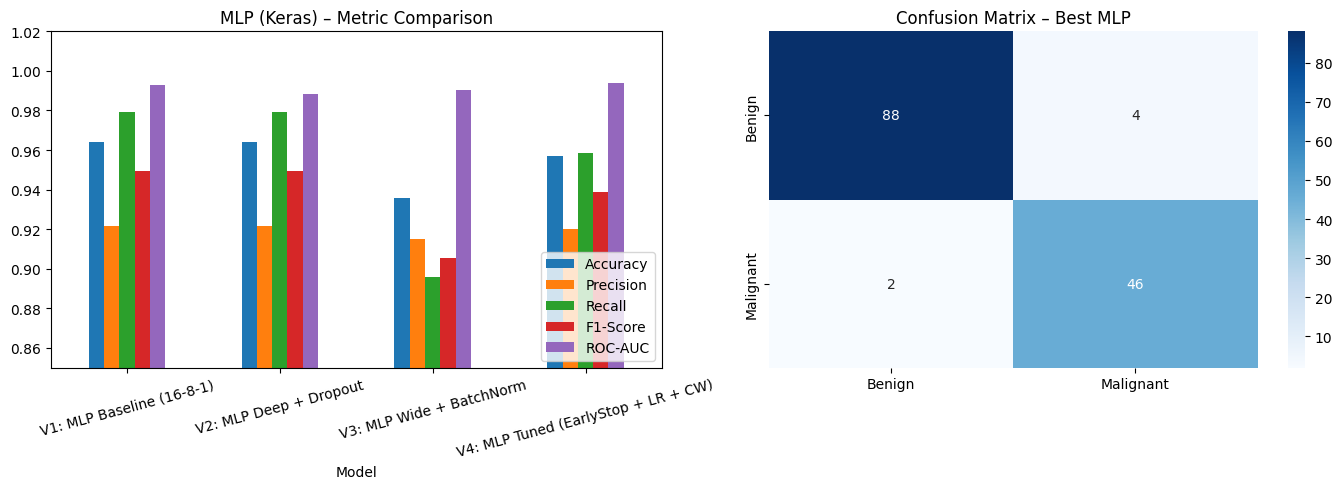

In [ ]:
# Metric bar chart + Confusion matrix of best
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
results_df[['Accuracy','Precision','Recall','F1-Score','ROC-AUC']].plot(kind='bar', ax=axes[0], rot=15)
axes[0].set_title('MLP (Keras) – Metric Comparison')
axes[0].set_ylim(0.85, 1.02)
axes[0].legend(loc='lower right')

best_pred = y_pred_v4  # usually the tuned one
cm = confusion_matrix(y_test, best_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[1],
            xticklabels=['Benign','Malignant'], yticklabels=['Benign','Malignant'])
axes[1].set_title('Confusion Matrix – Best MLP')
plt.tight_layout()
plt.show()

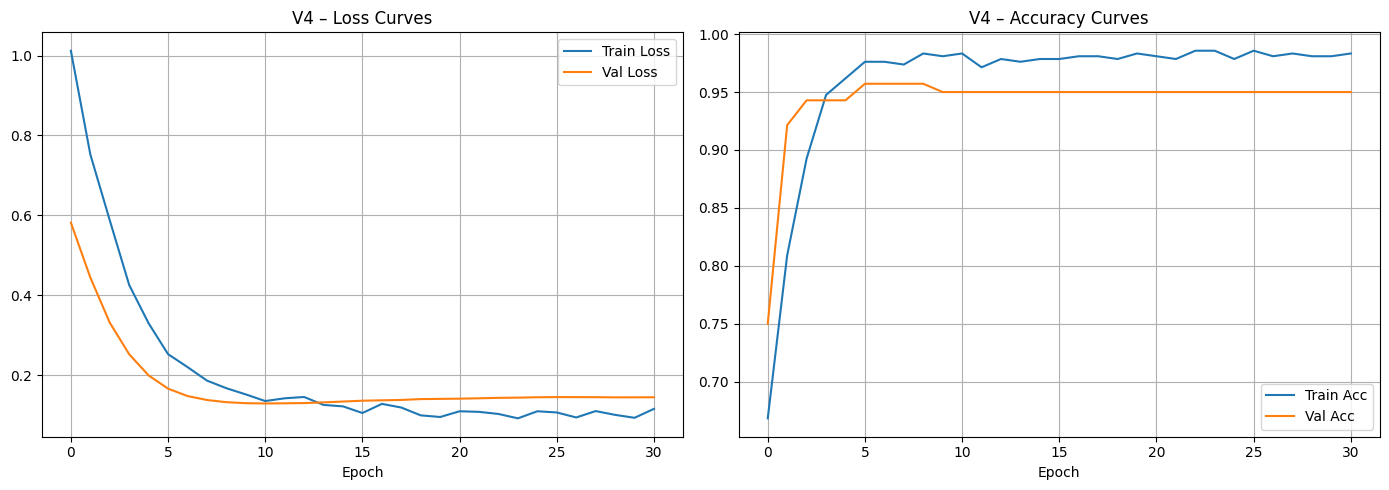

In [ ]:
# Training history of the best model (V4)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(history_v4.history['loss'], label='Train Loss')
axes[0].plot(history_v4.history['val_loss'], label='Val Loss')
axes[0].set_title('V4 – Loss Curves')
axes[0].set_xlabel('Epoch')
axes[0].legend()
axes[0].grid(True)

axes[1].plot(history_v4.history['accuracy'], label='Train Acc')
axes[1].plot(history_v4.history['val_accuracy'], label='Val Acc')
axes[1].set_title('V4 – Accuracy Curves')
axes[1].set_xlabel('Epoch')
axes[1].legend()
axes[1].grid(True)
plt.tight_layout()
plt.show()

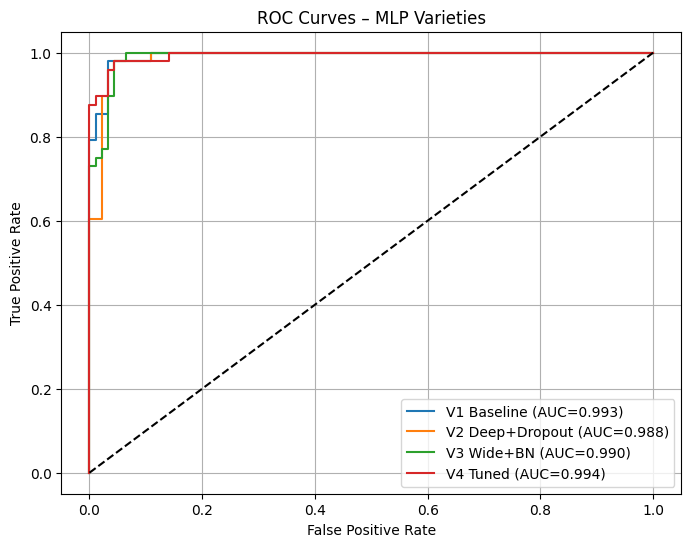

In [ ]:
# ROC Curves
plt.figure(figsize=(8, 6))
for name, prob in [
    ("V1 Baseline", y_prob_v1),
    ("V2 Deep+Dropout", y_prob_v2),
    ("V3 Wide+BN", y_prob_v3),
    ("V4 Tuned", y_prob_v4)
]:
    fpr, tpr, _ = roc_curve(y_test, prob)
    auc = roc_auc_score(y_test, prob)
    plt.plot(fpr, tpr, label=f'{name} (AUC={auc:.3f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves – MLP Varieties')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

## 4. Validation Method
- Stratified split: 60 % train / 20 % validation / 20 % test.
- EarlyStopping monitors validation loss (prevents overfitting).
- ReduceLROnPlateau adapts learning rate.
- Class weights handle the mild imbalance (≈2:1).
- Final metrics reported only on the held-out **test** set.

## 5. Conclusion
- Even a small MLP achieves high accuracy on this dataset.
- Regularisation (Dropout, L2, EarlyStopping) is essential to avoid overfitting.
- Variety 4 (tuned with callbacks + class weights) is the most robust.
- **Recommended model for group comparison**: V4.

## 6. Limitations & Improvements
| Limitation | Improvement |
|------------|-------------|
| Small dataset -> risk of overfitting | More data / stronger regularisation / data augmentation |
| No automatic architecture search | KerasTuner / Optuna for hyperparameter optimisation |
| Black-box nature | SHAP / LIME for explainability |
| Sensitive to random seed | Average multiple runs |
| Tabular data often beaten by tree ensembles | Still valuable as deep-learning demonstration |
